# torch.nn

In [365]:
## Setup

In [366]:
import random

import matplotlib.pyplot as plt
import seaborn as sns
from numpy.typing import NDArray

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

if torch.backends.mps.is_available():
    device = torch.device("mps")
    torch.set_default_device(device)
    generator = torch.Generator(device=device)
    print("MPS device found!")
else:
    device = torch.device("cpu")
    generator = torch.Generator(device=device)
    print("Defaulting to CPU!")

SEED = random.SystemRandom().randint(0, 2**32 - 1)
torch.manual_seed(SEED)
print(f"Random seed: {SEED}")

def to_numpy(tensor: torch.Tensor) -> NDArray:
    return tensor.detach().cpu().numpy().squeeze()

MPS device found!
Random seed: 1083414049


# Minibatch Updates

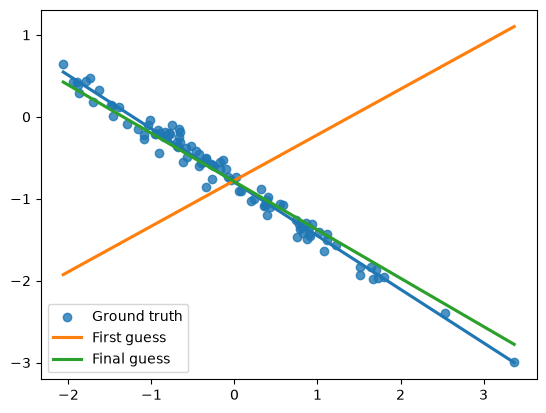

In [367]:
fig, ax = plt.subplots()

def add_to_plot(X: torch.Tensor, Y: torch.Tensor, label: str, isShowMarkers: bool = True):
    sns.regplot(
        x=to_numpy(X),
        y=to_numpy(Y),
        ax=ax,
        ci=None,
        scatter=isShowMarkers,
        label=label
    )

class LinearRegressionModel(nn.Module):
    """ Define the layers """
    def __init__(self, in_features, out_features) -> None:
        super().__init__()

        self.linear_layer = nn.Linear(in_features, out_features)

    """ Connect the layers in the forward pass """
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)


learning_rate, epochs = 0.01, 20
N, batch_size = 100, 10
D_x, D_y = 1, 1
X = torch.randn(N, D_x)

# Training Set
model_true: nn.Module = LinearRegressionModel(in_features=D_x,out_features=D_y)
with torch.no_grad():
    y_true: torch.Tensor = model_true(X) + 0.1*torch.randn(N, D_y)

add_to_plot(X, y_true, "Ground truth")

train_dataset = TensorDataset(X, y_true)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

# Model
model: nn.Module = LinearRegressionModel(in_features=D_x,out_features=D_y)
loss_fn = nn.MSELoss(reduction='sum')
optimiser = optim.Adam(params=model.parameters(), lr=learning_rate)

y_pred: torch.Tensor = model(X)
add_to_plot(X, y_pred, "First guess", False)

# Optimise
for epoch in range(epochs):
    for X_batch, y_batch in train_loader:
        optimiser.zero_grad()

        y_pred = model(X)
        loss: torch.Tensor = loss_fn(y_pred, y_true)

        loss.backward()
        optimiser.step()

y_pred = model(X)
add_to_plot(X, y_pred, "Final guess", False)


ax.legend()
plt.show()
